# Ecommerce Data Analysis

In [259]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [260]:
df = pd.read_csv('ecommerce_orders.csv')

In [261]:
df

,order_id,order_date,customer_id,customer_age,gender,region,city,product_category,product_name,quantity,unit_price_inr,discount_pct,shipping_fee_inr,sales_amount_inr,payment_method,order_status,shipping_days,customer_rating,sales_channel
0,ORD000001,2025-09-13,CUST00759,40.0,Female,Central,Gwalior,Clothing,T-Shirt,2,3148.15,20,60,5097.04,UPI,Delivered,4,5.0,Website
1,ORD000002,2024-05-10,CUST00159,38.0,Female,West,Mumbai,Clothing,Jacket,2,402.56,5,100,864.86,Net Banking,Cancelled,5,NaN,Website
2,ORD000003,2024-01-20,CUST00247,34.0,Male,East,Guwahati,Electronics,Power Bank,1,11957.23,0,120,12077.23,Cash on Delivery,Delivered,5,2.0,Website
3,ORD000004,2025-04-12,CUST01331,46.0,Male,West,Nagpur,Clothing,Sneakers,1,1597.71,0,120,1717.71,Cash on Delivery,Delivered,4,NaN,Website
4,ORD000005,2024-09-23,CUST01377,32.0,Male,South,Kochi,Home & Kitchen,Water Bottle,1,4933.79,5,120,4807.10,Debit Card,Delivered,1,4.0,Website
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,ORD002032,2025-01-24,CUST01227,68.0,Male,South,Coimbatore,Electronics,Smart Watch,1,13152.89,0,80,13232.89,Debit Card,Returned,0,NaN,Website
5008,ORD001022,2024-10-29,CUST00487,33.0,Male,Central,Jabalpur,Home & Kitchen,Water Bottle,2,3809.39,10,60,6916.90,Credit Card,Delivered,6,3.0,Marketplace
5009,ORD003311,2024-12-13,CUST00368,30.0,Female,Central,Jabalpur,Clothing,Jeans,2,2945.56,0,60,5951.12,Credit Card,Delivered,3,4.0,Mobile App
5010,ORD000034,2024-11-23,CUST01329,30.0,Female,North,Dehradun,Home & Kitchen,Water Bottle,3,4784.29,10,40,12957.58,UPI,Delivered,7,5.0,Website


In [262]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_age', 'gender',
       'region', 'city', 'product_category', 'product_name', 'quantity',
       'unit_price_inr', 'discount_pct', 'shipping_fee_inr',
       'sales_amount_inr', 'payment_method', 'order_status', 'shipping_days',
       'customer_rating', 'sales_channel'],
      dtype='str')

In [263]:
df.head(5)

,order_id,order_date,customer_id,customer_age,gender,region,city,product_category,product_name,quantity,unit_price_inr,discount_pct,shipping_fee_inr,sales_amount_inr,payment_method,order_status,shipping_days,customer_rating,sales_channel
0,ORD000001,2025-09-13,CUST00759,40.0,Female,Central,Gwalior,Clothing,T-Shirt,2,3148.15,20,60,5097.04,UPI,Delivered,4,5.0,Website
1,ORD000002,2024-05-10,CUST00159,38.0,Female,West,Mumbai,Clothing,Jacket,2,402.56,5,100,864.86,Net Banking,Cancelled,5,NaN,Website
2,ORD000003,2024-01-20,CUST00247,34.0,Male,East,Guwahati,Electronics,Power Bank,1,11957.23,0,120,12077.23,Cash on Delivery,Delivered,5,2.0,Website
3,ORD000004,2025-04-12,CUST01331,46.0,Male,West,Nagpur,Clothing,Sneakers,1,1597.71,0,120,1717.71,Cash on Delivery,Delivered,4,NaN,Website
4,ORD000005,2024-09-23,CUST01377,32.0,Male,South,Kochi,Home & Kitchen,Water Bottle,1,4933.79,5,120,4807.10,Debit Card,Delivered,1,4.0,Website


# 2. Data Cleaning

In [264]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5012 non-null   str    
 1   order_date        5012 non-null   str    
 2   customer_id       5012 non-null   str    
 3   customer_age      4887 non-null   float64
 4   gender            5012 non-null   str    
 5   region            5012 non-null   str    
 6   city              4962 non-null   str    
 7   product_category  5012 non-null   str    
 8   product_name      5012 non-null   str    
 9   quantity          5012 non-null   int64  
 10  unit_price_inr    5012 non-null   float64
 11  discount_pct      5012 non-null   int64  
 12  shipping_fee_inr  5012 non-null   int64  
 13  sales_amount_inr  5012 non-null   float64
 14  payment_method    4972 non-null   str    
 15  order_status      5012 non-null   str    
 16  shipping_days     5012 non-null   int64  
 17  custom

In [265]:
for col in ['customer_age','city','payment_method','customer_rating']:
    print(col, df[col].isnull().sum(),sep= '----> ')

customer_age----> 125
city----> 50
payment_method----> 40
customer_rating----> 1454


In [266]:
df.duplicated().any()

np.True_

In [267]:
age_mean = df['customer_age'].mean()

In [268]:
df['customer_age'] = df['customer_age'].fillna(age_mean)

In [269]:
rating_mean = df['customer_rating'].mean()

In [270]:
df['customer_rating'] = df['customer_rating'].fillna(rating_mean)

In [271]:
for col in ['customer_age','customer_rating']:
    print(col, df[col].isnull().sum(), sep = '--->')

customer_age--->0
customer_rating--->0


In [272]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5012 non-null   str    
 1   order_date        5012 non-null   str    
 2   customer_id       5012 non-null   str    
 3   customer_age      5012 non-null   float64
 4   gender            5012 non-null   str    
 5   region            5012 non-null   str    
 6   city              4962 non-null   str    
 7   product_category  5012 non-null   str    
 8   product_name      5012 non-null   str    
 9   quantity          5012 non-null   int64  
 10  unit_price_inr    5012 non-null   float64
 11  discount_pct      5012 non-null   int64  
 12  shipping_fee_inr  5012 non-null   int64  
 13  sales_amount_inr  5012 non-null   float64
 14  payment_method    4972 non-null   str    
 15  order_status      5012 non-null   str    
 16  shipping_days     5012 non-null   int64  
 17  custom

In [273]:
df['city'].mode()


0    Bengaluru
1    Hyderabad
Name: city, dtype: str

In [274]:
df['city'] = df['city'].fillna('unknown')

In [275]:
df['payment_method'] = df['payment_method'].fillna(df['payment_method'].mode()[0])

In [276]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5012 non-null   str    
 1   order_date        5012 non-null   str    
 2   customer_id       5012 non-null   str    
 3   customer_age      5012 non-null   float64
 4   gender            5012 non-null   str    
 5   region            5012 non-null   str    
 6   city              5012 non-null   str    
 7   product_category  5012 non-null   str    
 8   product_name      5012 non-null   str    
 9   quantity          5012 non-null   int64  
 10  unit_price_inr    5012 non-null   float64
 11  discount_pct      5012 non-null   int64  
 12  shipping_fee_inr  5012 non-null   int64  
 13  sales_amount_inr  5012 non-null   float64
 14  payment_method    5012 non-null   str    
 15  order_status      5012 non-null   str    
 16  shipping_days     5012 non-null   int64  
 17  custom

In [277]:
df.shape

(5012, 19)

In [278]:
df

,order_id,order_date,customer_id,customer_age,gender,region,city,product_category,product_name,quantity,unit_price_inr,discount_pct,shipping_fee_inr,sales_amount_inr,payment_method,order_status,shipping_days,customer_rating,sales_channel
0,ORD000001,2025-09-13,CUST00759,40.0,Female,Central,Gwalior,Clothing,T-Shirt,2,3148.15,20,60,5097.04,UPI,Delivered,4,5.000000,Website
1,ORD000002,2024-05-10,CUST00159,38.0,Female,West,Mumbai,Clothing,Jacket,2,402.56,5,100,864.86,Net Banking,Cancelled,5,3.850759,Website
2,ORD000003,2024-01-20,CUST00247,34.0,Male,East,Guwahati,Electronics,Power Bank,1,11957.23,0,120,12077.23,Cash on Delivery,Delivered,5,2.000000,Website
3,ORD000004,2025-04-12,CUST01331,46.0,Male,West,Nagpur,Clothing,Sneakers,1,1597.71,0,120,1717.71,Cash on Delivery,Delivered,4,3.850759,Website
4,ORD000005,2024-09-23,CUST01377,32.0,Male,South,Kochi,Home & Kitchen,Water Bottle,1,4933.79,5,120,4807.10,Debit Card,Delivered,1,4.000000,Website
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,ORD002032,2025-01-24,CUST01227,68.0,Male,South,Coimbatore,Electronics,Smart Watch,1,13152.89,0,80,13232.89,Debit Card,Returned,0,3.850759,Website
5008,ORD001022,2024-10-29,CUST00487,33.0,Male,Central,Jabalpur,Home & Kitchen,Water Bottle,2,3809.39,10,60,6916.90,Credit Card,Delivered,6,3.000000,Marketplace
5009,ORD003311,2024-12-13,CUST00368,30.0,Female,Central,Jabalpur,Clothing,Jeans,2,2945.56,0,60,5951.12,Credit Card,Delivered,3,4.000000,Mobile App
5010,ORD000034,2024-11-23,CUST01329,30.0,Female,North,Dehradun,Home & Kitchen,Water Bottle,3,4784.29,10,40,12957.58,UPI,Delivered,7,5.000000,Website


# 3. Transform the dataset (Data Manipulation / Data Transformation)

In [279]:
df['order_id'].unique()

<StringArray>
['ORD000001', 'ORD000002', 'ORD000003', 'ORD000004', 'ORD000005', 'ORD000006',
 'ORD000007', 'ORD000008', 'ORD000009', 'ORD000010',
 ...
 'ORD004991', 'ORD004992', 'ORD004993', 'ORD004994', 'ORD004995', 'ORD004996',
 'ORD004997', 'ORD004998', 'ORD004999', 'ORD005000']
Length: 5000, dtype: str

In [280]:
df['order_id'].duplicated().sum()

np.int64(12)

In [281]:
df = df.drop_duplicates(subset= 'order_id', keep = 'first')

In [282]:
df['order_id'].duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Name: order_id, Length: 5000, dtype: bool

In [283]:
df

,order_id,order_date,customer_id,customer_age,gender,region,city,product_category,product_name,quantity,unit_price_inr,discount_pct,shipping_fee_inr,sales_amount_inr,payment_method,order_status,shipping_days,customer_rating,sales_channel
0,ORD000001,2025-09-13,CUST00759,40.0,Female,Central,Gwalior,Clothing,T-Shirt,2,3148.15,20,60,5097.04,UPI,Delivered,4,5.000000,Website
1,ORD000002,2024-05-10,CUST00159,38.0,Female,West,Mumbai,Clothing,Jacket,2,402.56,5,100,864.86,Net Banking,Cancelled,5,3.850759,Website
2,ORD000003,2024-01-20,CUST00247,34.0,Male,East,Guwahati,Electronics,Power Bank,1,11957.23,0,120,12077.23,Cash on Delivery,Delivered,5,2.000000,Website
3,ORD000004,2025-04-12,CUST01331,46.0,Male,West,Nagpur,Clothing,Sneakers,1,1597.71,0,120,1717.71,Cash on Delivery,Delivered,4,3.850759,Website
4,ORD000005,2024-09-23,CUST01377,32.0,Male,South,Kochi,Home & Kitchen,Water Bottle,1,4933.79,5,120,4807.10,Debit Card,Delivered,1,4.000000,Website
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,ORD004996,2025-11-29,CUST01614,35.0,Female,North,Dehradun,Home & Kitchen,Desk Lamp,2,837.20,0,100,1774.40,Credit Card,Delivered,3,4.000000,Marketplace
4996,ORD004997,2024-07-28,CUST00107,25.0,Male,West,Pune,Electronics,Smart Watch,3,9087.16,0,0,27261.48,Credit Card,Delivered,5,3.000000,Mobile App
4997,ORD004998,2024-11-19,CUST00435,47.0,Male,East,Ranchi,Books,Business Strategy,1,331.95,15,40,322.16,Net Banking,Delivered,5,3.850759,Website
4998,ORD004999,2024-07-08,CUST01017,40.0,Female,Central,Bhopal,Clothing,Jacket,2,2735.14,0,80,5550.28,Debit Card,Delivered,7,3.000000,Website


In [284]:
df['customer_id'].duplicated().sum()

np.int64(3310)

In [285]:
df['customer_id'].nunique()

1690

In [286]:
df['customer_id'].value_counts().head(10)

customer_id
CUST01567    9
CUST01575    9
CUST00048    9
CUST00508    8
CUST00377    8
CUST00323    8
CUST01730    8
CUST00791    8
CUST00252    7
CUST00690    7
Name: count, dtype: int64

In [287]:
df.duplicated().sum()

np.int64(0)

In [288]:
df['order_id'].duplicated().sum()

np.int64(0)

# Exploratory Data Analysis

In [289]:
df['sales_amount_inr'].sum()

np.float64(26808197.919999998)

In [290]:
category_sales = df.groupby('product_category')['sales_amount_inr'].sum().sort_values(ascending= False).reset_index()

In [291]:
print("Total sales", df['sales_amount_inr'].sum())
print("Category sales",category_sales.sum())

Total sales 26808197.919999998
Category sales product_category    ElectronicsHome & KitchenSportsClothingBeautyT...
sales_amount_inr                                          26808197.92
dtype: object


In [292]:
print(category_sales)

  product_category  sales_amount_inr
0      Electronics       13724521.37
1   Home & Kitchen        4059819.32
2           Sports        3413931.54
3         Clothing        3050578.55
4           Beauty        1042917.75
5             Toys         989113.62
6            Books         527315.77


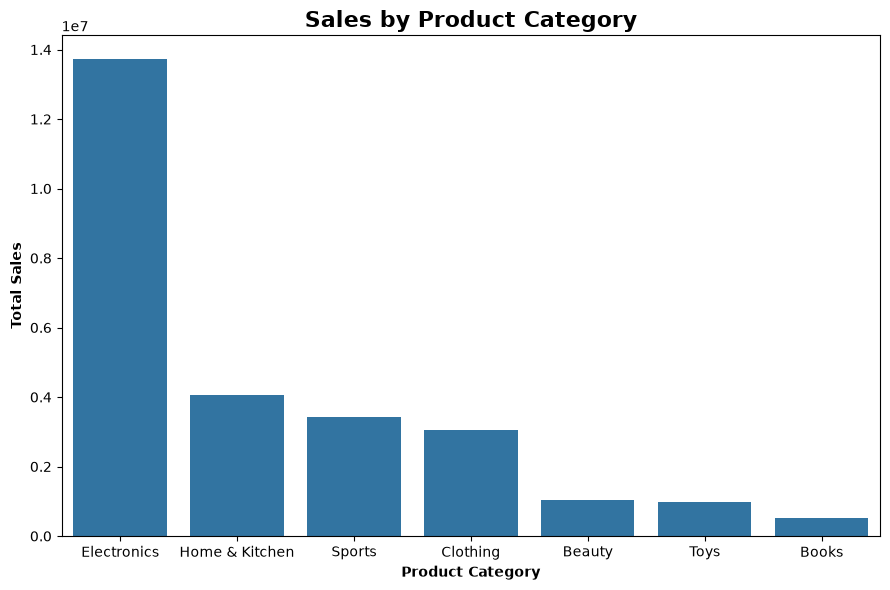

In [293]:
plt.figure(figsize= (9,6))
sns.barplot(
    data=category_sales,
    x='product_category',
    y='sales_amount_inr'
)
plt.title('Sales by Product Category', fontsize= 16, fontweight= 'bold', color = 'black'),
plt.xlabel('Product Category', fontweight='bold'),
plt.ylabel('Total Sales',fontweight= 'bold'),
plt.tight_layout()
plt.show()

In [294]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [295]:
monthly_sales = (df.groupby(df['order_date'].dt.to_period('M'))['sales_amount_inr'].sum().reset_index())

monthly_sales['order_date'] = monthly_sales['order_date'].astype('str')
print(monthly_sales)


   order_date  sales_amount_inr
0     2024-01        1102269.68
1     2024-02         979765.00
2     2024-03        1035405.04
3     2024-04        1410745.09
4     2024-05        1059521.43
5     2024-06        1169695.90
6     2024-07         945604.78
7     2024-08        1225289.47
8     2024-09        1279408.99
9     2024-10        1467035.66
10    2024-11         962739.39
11    2024-12         976630.67
12    2025-01        1050256.97
13    2025-02         921788.21
14    2025-03        1279250.22
15    2025-04        1323465.13
16    2025-05        1259592.82
17    2025-06        1108453.71
18    2025-07        1248675.24
19    2025-08         825504.04
20    2025-09        1068695.16
21    2025-10         939423.81
22    2025-11        1065996.88
23    2025-12        1102984.63


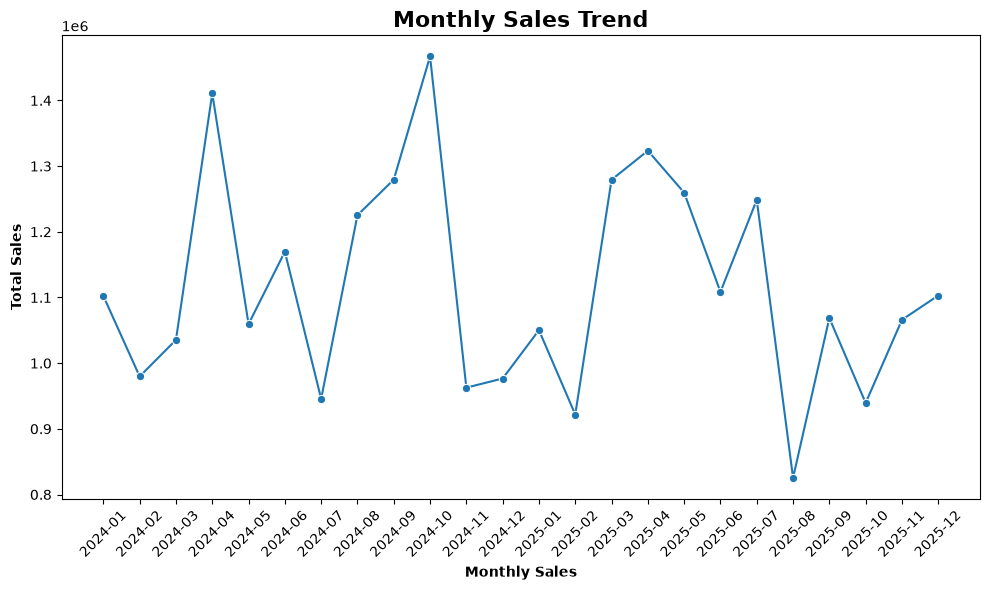

In [296]:
plt.figure(figsize=(10,6))
sns.lineplot(data= monthly_sales, x='order_date', y = 'sales_amount_inr',marker= 'o')

plt.title('Monthly Sales Trend', fontsize=16, fontweight='bold')
plt.xlabel('Monthly Sales', fontweight='bold')
plt.xticks(rotation=45)
plt.ylabel('Total Sales', fontweight= 'bold')
plt.tight_layout()
plt.show()

In [297]:
print(monthly_sales.columns)

Index(['order_date', 'sales_amount_inr'], dtype='str')


In [298]:
status_count = df['order_status'].value_counts()
print(status_count)

order_status
Delivered     3867
Returned       431
In Transit     355
Cancelled      347
Name: count, dtype: int64


In [299]:
percentage_status = df['order_status'].value_counts(normalize=True)*100
print(percentage_status)

order_status
Delivered     77.34
Returned       8.62
In Transit     7.10
Cancelled      6.94
Name: proportion, dtype: float64


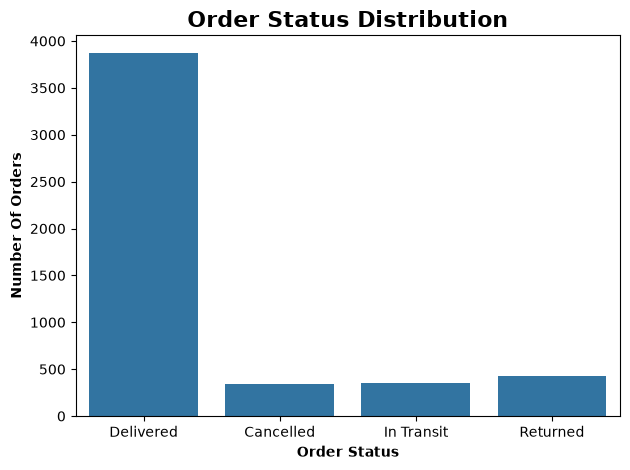

In [300]:
plt.Figure(figsize=(10,6))
sns.countplot(data=df, x= 'order_status')
plt.title('Order Status Distribution', fontsize = 16, fontweight= 'bold'),
plt.xlabel('Order Status', fontweight='bold')
plt.ylabel('Number Of Orders', fontweight = 'bold')
plt.tight_layout()
plt.show()

In [301]:
payment_counts = df['payment_method'].value_counts()
print(payment_counts)

payment_method
UPI                 1750
Credit Card         1111
Debit Card           909
Cash on Delivery     648
Net Banking          582
Name: count, dtype: int64


In [302]:
payment_percentage = df['payment_method'].value_counts(normalize=True)*100
payment_percentage.round(2)

payment_method
UPI                 35.00
Credit Card         22.22
Debit Card          18.18
Cash on Delivery    12.96
Net Banking         11.64
Name: proportion, dtype: float64

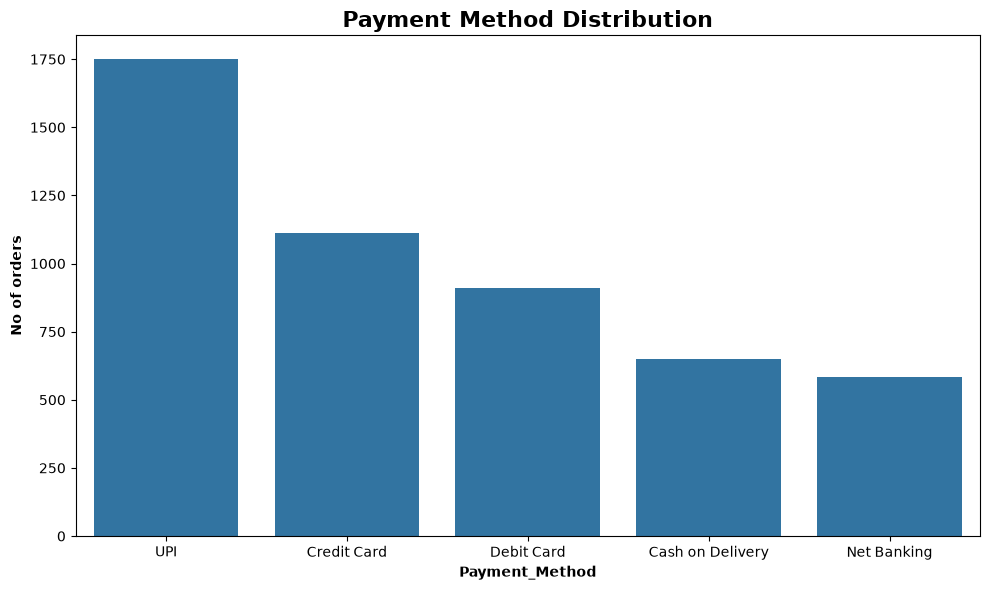

In [303]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x = 'payment_method', order = df['payment_method'].value_counts().index)

plt.title('Payment Method Distribution', fontsize = 16, fontweight = 'bold')
plt.xlabel('Payment_Method', fontweight = 'bold')
plt.ylabel('No of orders', fontweight = 'bold')
plt.tight_layout()
plt.show()

In [304]:
payment_sales = (df.groupby('payment_method')['sales_amount_inr'].sum().sort_values(ascending=False))

payment_sales


payment_method
UPI                 8971425.81
Credit Card         5944164.53
Debit Card          4685970.42
Cash on Delivery    3672245.96
Net Banking         3534391.20
Name: sales_amount_inr, dtype: float64

In [305]:
region_sales = (df.groupby('region')['sales_amount_inr'].sum().sort_values(ascending = False))

region_sales

region
South      7119902.42
North      6139585.62
West       5530862.97
East       4499244.22
Central    3518602.69
Name: sales_amount_inr, dtype: float64

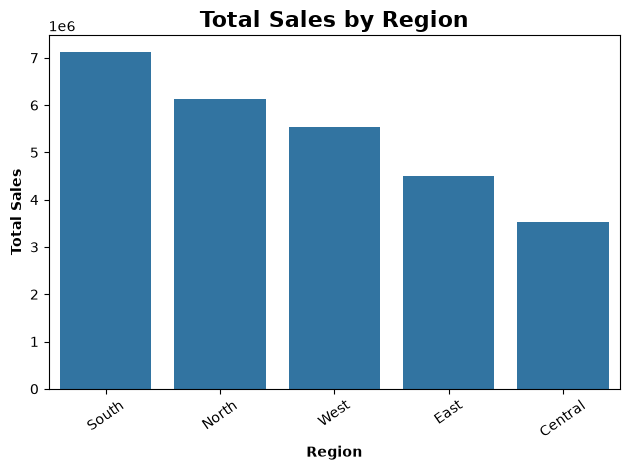

In [306]:
plt.Figure(figsize=(10,6))
sns.barplot(data= df, x = 'region', y='sales_amount_inr', estimator='sum', errorbar= None, order= region_sales.index)

plt.title('Total Sales by Region', fontsize = 16, fontweight = 'bold')
plt.xlabel('Region', fontweight = 'bold')
plt.ylabel('Total Sales', fontweight = 'bold')
plt.xticks(rotation = 35)
plt.tight_layout()
plt.show()

In [307]:
product_sales = df.groupby('product_name')['sales_amount_inr'].sum().sort_values(ascending=False).head(10).reset_index()

product_sales

,product_name,sales_amount_inr
0,Wireless Earbuds,2936494.83
1,Power Bank,2863130.08
2,USB-C Hub,2815369.38
3,Bluetooth Speaker,2747163.10
4,Smart Watch,2362363.98
5,Cookware Set,857923.36
6,Storage Set,854255.54
7,Cricket Bat,818407.05
8,Mixer Grinder,815817.18
9,Water Bottle,779858.58


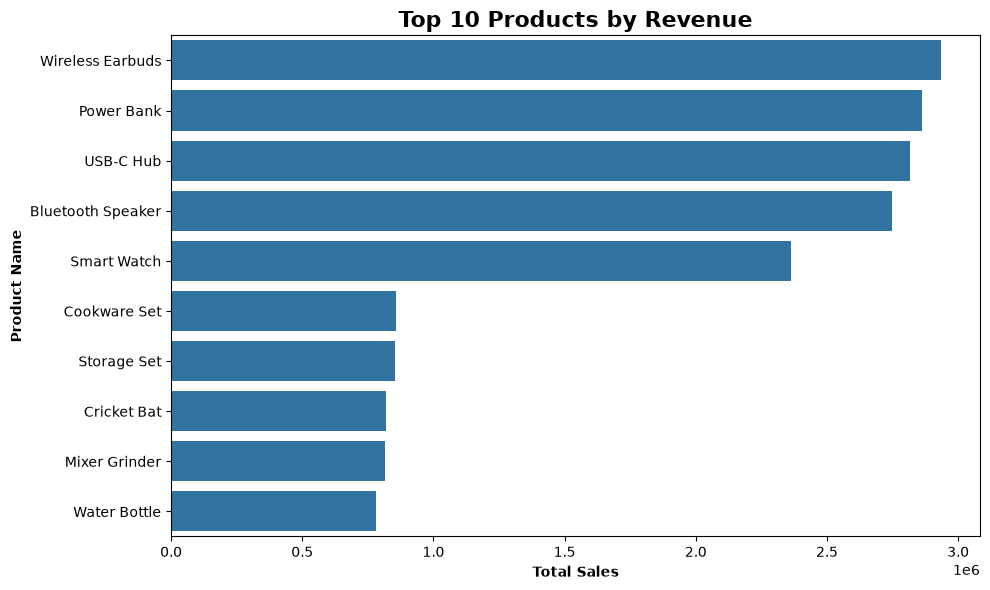

In [308]:
plt.figure(figsize=(10,6))

sns.barplot(data = product_sales, x = 'sales_amount_inr', y = 'product_name', errorbar=None)

plt.title('Top 10 Products by Revenue', fontsize= 16, fontweight= 'bold')
plt.xlabel('Total Sales', fontweight= 'bold')
plt.ylabel('Product Name', fontweight = 'bold')
plt.tight_layout()
plt.show()

In [309]:
product_quantity = df.groupby('product_name')['quantity'].sum().sort_values(ascending=False).head(10).reset_index()

product_quantity

,product_name,quantity
0,Sneakers,395
1,Jeans,383
2,Power Bank,381
3,Wireless Earbuds,381
4,Jacket,379
5,Bluetooth Speaker,359
6,USB-C Hub,333
7,T-Shirt,328
8,Backpack,327
9,Storage Set,308


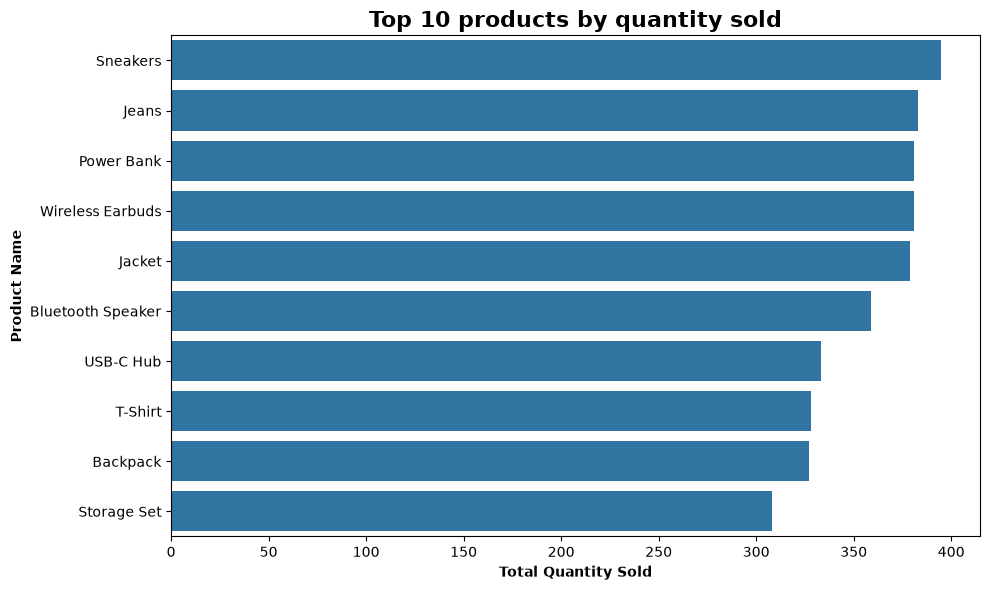

In [310]:
plt.figure(figsize= (10,6))
sns.barplot(data =product_quantity, x = 'quantity', y= 'product_name', errorbar=None)

plt.title('Top 10 products by quantity sold', fontsize = 16, fontweight = 'bold')
plt.xlabel('Total Quantity Sold', fontweight= 'bold')
plt.ylabel('Product Name', fontweight='bold')
plt.tight_layout()
plt.show()

In [311]:
customer_sales = (df.groupby('customer_id')['sales_amount_inr'].sum().sort_values(ascending=False).head(10).reset_index())

customer_sales

,customer_id,sales_amount_inr
0,CUST01672,113017.45
1,CUST01785,104449.97
2,CUST01156,100719.41
3,CUST00829,87733.48
4,CUST00412,83723.12
5,CUST01786,80750.92
6,CUST00078,79833.88
7,CUST00688,79404.67
8,CUST01545,79298.37
9,CUST00676,77951.92


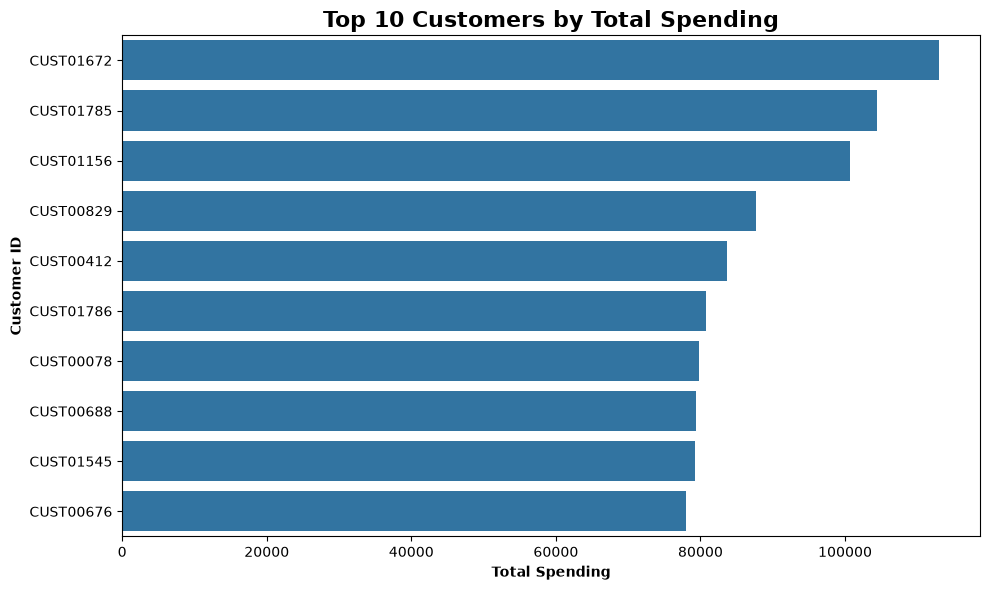

In [312]:
plt.figure(figsize=(10,6))
sns.barplot(data= customer_sales, x = 'sales_amount_inr', y = 'customer_id', errorbar = None)

plt.title('Top 10 Customers by Total Spending', fontsize = 16, fontweight= 'bold')
plt.xlabel('Total Spending', fontweight = 'bold')
plt.ylabel('Customer ID', fontweight= 'bold')
plt.tight_layout()
plt.show()

In [313]:
channel_sales = (df.groupby('sales_channel')['sales_amount_inr'].sum().sort_values(ascending=False).reset_index())

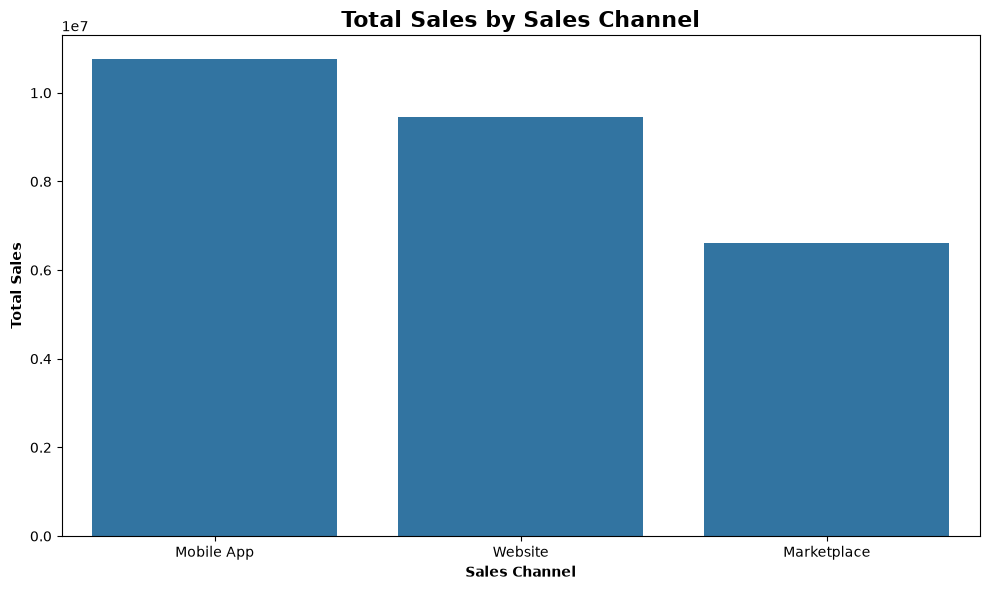

In [314]:
plt.figure(figsize=(10,6))
sns.barplot(data = channel_sales, x = 'sales_channel', y = 'sales_amount_inr', errorbar = None)

plt.title('Total Sales by Sales Channel', fontsize = 16, fontweight= 'bold')
plt.xlabel('Sales Channel', fontweight = 'bold')
plt.ylabel('Total Sales', fontweight = 'bold')
plt.tight_layout()
plt.show()

In [315]:
channel_orders = df['sales_channel'].value_counts()
channel_orders

sales_channel
Mobile App     2042
Website        1778
Marketplace    1180
Name: count, dtype: int64

In [316]:
rating_counts = df['customer_rating'].value_counts().sort_index()

print(rating_counts)

customer_rating
1.000000     161
2.000000     297
3.000000     635
3.850759    1452
4.000000    1278
5.000000    1177
Name: count, dtype: int64


In [317]:
average_rating = df['customer_rating'].mean()
average_rating.round(2)


np.float64(3.85)

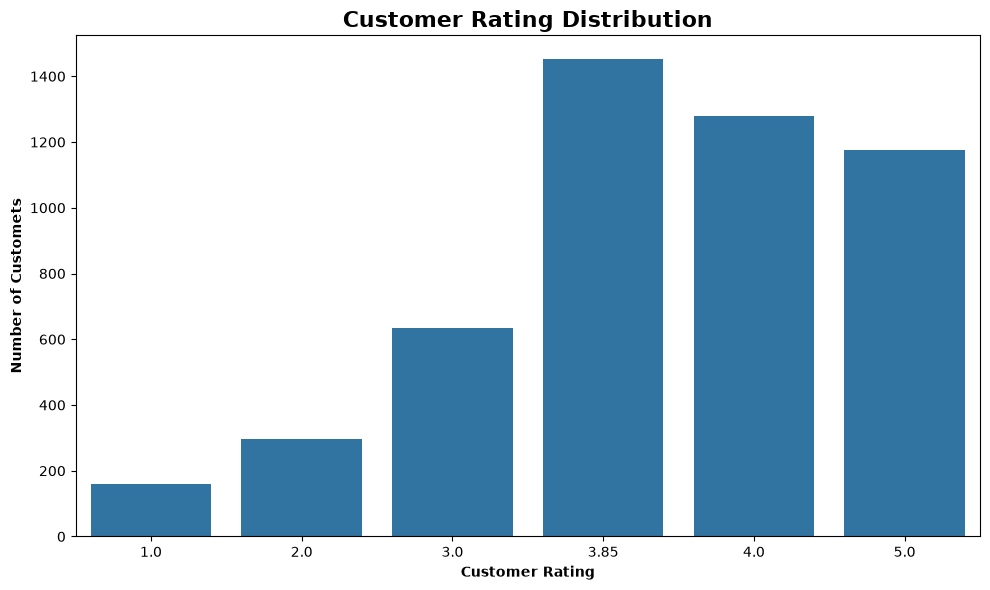

In [ ]:
df['customer_rating'] = df['customer_rating'].round(2)

plt.figure(figsize=(10,6))
sns.countplot( data = df, x = 'customer_rating')

plt.title('Customer Rating Distribution', fontsize = 16, fontweight = 'bold')
plt.xlabel('Customer Rating', fontweight = 'bold')
plt.ylabel('Number of Customets', fontweight = 'bold')
plt.tight_layout()
plt.show()

In [325]:
category_ratings = df.groupby('product_category')['customer_rating'].mean().sort_values(ascending=False).round(2)
category_ratings

product_category
Beauty            3.93
Electronics       3.89
Clothing          3.86
Sports            3.85
Books             3.81
Toys              3.81
Home & Kitchen    3.78
Name: customer_rating, dtype: float64

In [331]:
total_sales = df['sales_amount_inr'].sum().round(2)
total_orders = df['order_id'].nunique()
print("Total Sales", total_sales)
print("Total Orders", total_orders)
print('total_customer',df['customer_id'].nunique())
average_order_value = total_sales / total_orders
print(f"Average Order value: {average_order_value:.2f}")


Total Sales 26808197.92
Total Orders 5000
total_customer 1690
Average Order value: 5361.64
